# <center><font color = "iceblue"> TRABALHO FINAL - A2 - ANÁLISE EXPLORATÓRIA DE DADOS E VISUALIZAÇÕES
## <center><font color = "blue:red"> O Cenário Nacional da Educação Especial no Brasil - Uma visão estístico-temporal entre 2015 e 2025

**Alunos: Ian Luca Marinho Aguiar / João Pedro Menezes Barros Dantas de Souza / Davi da Cunha Ribeiro <br>
Turma: 1708-OBG**

Neste notebook, respondemos a sete perguntas sobre a educação especial no Brasil. Usamos as Sinopses Estatísticas da Educação Básica de 2015, 2020 e 2025 e o Censo Demográfico de 2022.

1. Como evoluíram as matrículas da educação especial entre 2015 e 2025, em comparação com o total da educação básica?
2. Como as matrículas se dividem entre deficiências, TEA e altas habilidades, e como essa composição mudou ao longo dos anos?
3. Em que etapas de ensino estão esses alunos, e a presença deles diminui ao longo da trajetória escolar?
4. Qual a parcela desses alunos em classes comuns, e como ela difere entre rede pública e privada?
5. O crescimento e a inclusão vistos no país se repetem em todas as regiões e estados, ou a média nacional é puxada por poucos estados?
6. Como o peso da educação especial nas matrículas varia entre os estados, e ele acompanha a proporção de pessoas com deficiência e autismo medida pelo IBGE?
7. Os estados onde a educação especial mais cresceu são os que mais ampliaram a inclusão em classes comuns?

- [Proposta do trabalho](Projeto%20e%20proposta/Proposta_Educacao_Especial_Brasil.pdf)
- [Guia das bases de dados](exp-requisitos.md)

# <font color="blue:red">-------------------------------------------------------------------------------------------
# <font color="iceblue"><p style="text-align: justify"><center>IMPORTAÇÕES</p>
# <font color="blue:red">-------------------------------------------------------------------------------------------

In [ ]:
# Manipulação dos dados
import pandas as pd
import numpy as np

# Visualizações
import plotly.express as px
from matplotlib.ticker import FuncFormatter
import matplotlib.pyplot as plt
from IPython.display import display
from io import StringIO

## <font color = "iceblue"> PERGUNTA 1: <font color = "skyblue">Como evoluíram as matrículas da educação especial entre 2015 e 2025, em comparação com o total da educação básica?

## 1.1) Limpeza dos dados

As Sinopses Estatísticas da Educação Básica, disponibilizadas anualmente pelo INEP, são dadas no formato *xlsx*, construída para a **leitura humana**. Isso implica que a base de dados contém inconsistências que afetam o tratamento dos dados para formar as visualizações. Como pode ser visto abaixo, caso não façamos uma limpeza nas linhas e colunas das tabelas dadas, as colunas são dadas como *Unnamed*, isto é, sem nome:

In [ ]:
# Leitura das planilhas usadas nas perguntas 1 a 3
with pd.ExcelFile("Sinopse_Estatistica_da_Educação_Basica_2025_V2.xlsx") as bd_25:
    tb_11_2025 = pd.read_excel(bd_25, sheet_name="Educação Básica 1.1")
    tb_155_2025 = pd.read_excel(bd_25, sheet_name="Educação Especial 1.55")
    tb_158_2025 = pd.read_excel(bd_25, sheet_name="1.58")

# Usamos a versão da sinopse de 2020 atualizada em 08/03/2021.
with pd.ExcelFile("Sinopse_Estatistica_da_Educação_Basica_2020.xlsx") as bd_20:
    tb_11_2020 = pd.read_excel(bd_20, sheet_name="Educação Básica 1.1")
    tb_138_2020 = pd.read_excel(bd_20, sheet_name="Educação Especial 1.38")
    tb_143_2020 = pd.read_excel(bd_20, sheet_name="1.43")
    tb_149_2020 = pd.read_excel(bd_20, sheet_name="1.49")

with pd.ExcelFile("Sinopse_Estatistica_da_Educação_Basica_2015.xlsx") as bd_15:
    tb_11_2015 = pd.read_excel(bd_15, sheet_name="Educação Básica 1.1")
    tb_138_2015 = pd.read_excel(bd_15, sheet_name="Educação Especial 1.38")
    tb_143_2015 = pd.read_excel(bd_15, sheet_name="1.43")
    tb_149_2015 = pd.read_excel(bd_15, sheet_name="1.49")

# Veja como aparecem os nomes das colunas da tabela 1.58 de 2025.
print(tb_158_2025.columns)

Assim, fizemos a função *limpar_1(df)*, que recebe o dataframe e o padroniza com base na tabela mais recente (de 2025). A função normaliza as linhas para evitar que a divergência de informações implique em inconsistências nos cálculos. Além disso, fizemos com que as colunas ficassem com os mesmos nomes para facilitar ao relacioná-las.

In [74]:
#Este dicionário servirá para a organização dos próximos códigos
tabelas = {
    2015: (tb_11_2015, tb_138_2015),
    2020: (tb_11_2020, tb_138_2020),
    2025: (tb_11_2025, tb_155_2025)}

# Função para limpar a tabela e retirar as inconsistências que as células mescladas induzem na análise dos dados

def limpar_1(df: pd.DataFrame) -> pd.DataFrame:
    """Esta função seleciona exatamente as colunas de identificação regional, estadual e municipal e relaciona com a linha de total de 
   matrículas no Ensino Básico brasileiro. 

    Parâmetros:
        df: pd.DataFrame - Tabela a ser padronizada e modificada
    Retornos:
        pd.DataFrame - Retorna um DataFrame contendo a tabela limpa com somente os totais de matrículas no Ensino Básico em cada
        ano, para cada região, estado e município.
    """
    df = df.iloc[:, :5].copy()
    df.columns = ["Região", "Estado", "Município", "IBGE", "Total"]

    df["Total"] = pd.to_numeric(df["Total"], errors="coerce")
    df["IBGE"] = pd.to_numeric(df["IBGE"], errors="coerce").astype("Int64")
    df = df[df["Total"].notna()].copy()
    
    for coluna in ["Região", "Estado", "Município"]:
        df[coluna] = df[coluna].astype("string").str.strip().replace("", pd.NA)

    df["id"] = "REG:" + df["Região"]
    df.loc[df["Estado"].notna(), "id"] = "UF:" + df["Estado"]
    df.loc[df["IBGE"].notna(), "id"] = "MUN:" + df["IBGE"].astype("string")

    df = df.dropna(subset=["id"])
    return df.set_index("id")

## 1.2) Montagem dos DataFrames (*views*)

Aqui, a resposta será dada por meio da porcentagem de matrículas de alunos especiais com relação às matrículas totais. A visualização da variação percentual de participação de alunos especiais será dada por meio uma série temporal com intervalos de 5 anos (por isso pegamos os anos de 2015, 2020 e 2025).



In [ ]:
# Monta a view a partir das localidades de 2025 (escolhemos utilizar os padrões de 2025 e não os de 2015 e 2020)
view_geral = limpar_1(tb_11_2025)[["Região", "Estado", "Município", "IBGE"]].copy()

# Calcula os percentuais
for ano, (basica, especial) in tabelas.items():
    total = limpar_1(basica)["Total"]
    esp = limpar_1(especial)["Total"]

    view_geral[ano] = (esp / total.where(total != 0) * 100).round(2)


view_geral = view_geral.reset_index(drop=True) # Apenas para fins de retirar informações para outras views


# Views individuais (Nacional, Regional)

view_nacional = view_geral.loc[view_geral["Região"] == "Brasil"].melt(
    value_vars=[2015, 2020, 2025],
    var_name="Ano",
    value_name="Percentual"
)
view_regional = view_geral[view_geral['Estado'].isna() & view_geral['Município'].isna() & view_geral['IBGE'].isna()]

display(view_nacional)
display(view_regional)

# Projetando as séries temporais:
fig_nacional = px.line(view_nacional, x = "Ano", y = "Percentual", title = "Evolução da Educação Especial no Brasil (2015–2025)", 
              labels = {"Ano": "Ano", "Percentual": "Matrículas da Educação Especial (%)"})


fig_nacional.show()

## 1.3) Leitura dos resultados
Percebe-se que a quantidade de matrículas de alunos especiais aumentou em **3,43** pontos percentuais (**3,43pp**) no cenário nacional, denotando maior representatividade de alunos neurodivergentes e deficientes no cenário nacional. É importante entender que o aumento da participação de alunos especiais na Educação Básica **não** significa uma **melhora** no atendimento para estes grupos. Na verdade, essa estatística serve de incentivo para os avanços na rede básica de educação para a inclusão deste público. Além disso, pode-se observar que em todas as regiões e estados houve um aumento significativo de alunos especiais.

*Os dados cobrem três anos específicos, não todos os anos entre 2015 e 2025.*

**Fonte:** [INEP — Sinopses Estatísticas da Educação Básica](https://www.gov.br/inep/pt-br/acesso-a-informacao/dados-abertos/sinopses-estatisticas/educacao-basica).

## <font color = "iceblue"> PERGUNTA 2: <font color = "skyblue">Como as matrículas se dividem entre deficiências, TEA e altas habilidades, e como essa composição mudou ao longo dos anos?

## 2.1) Limpeza e padronização dos dados

Assim como nas questões anteriores, foi preciso realizar um tratamento dos dados devido à formatação das sinopses estatísticas. Dessa vez, utilizamos as tabelas referentes às classes comuns e exclusivas de 2015 e 2020, além da tabela unificada de 2025, que junta em uma tabela as classes comuns e exclusivas, diferentemente dos anos anteriores. Outro detalhe importante é que algumas classificações sofreram alterações entre os anos, principalmente aquelas relacionadas ao autismo/TEA. Por isso, inclusive, somamos as quatro classificações de 2015 que separavam alunos com autismo, Síndrome de Asperger, Síndrome de Rett e Transtorno Desintegrativo da Infância (TDI). Mesmo que esta soma não seja equivalente às colunas de autismo de 2020 e TEA's de 2025, é a melhor aproximação a ser feita sem perdas de dados. 

Portanto, fizemos a função *limpar_2(df)*, que seleciona os dados referentes ao Brasil e converte os valores das colunas para o formato numérico. Além disso, organizamos as tabelas no dicionário *tabelas_2*, facilitando a comparação das matrículas de cada categoria entre os três anos.

In [76]:

# Organiza as tabelas utilizadas na pergunta 2
tabelas_2 = {
    2015: [tb_143_2015, tb_149_2015],
    2020: [tb_143_2020, tb_149_2020],
    2025: [tb_158_2025]}

# Seleciona os dados nacionais e converte os valores em números
def limpar_2(df: pd.DataFrame) -> pd.Series:
    """Seleciona a linha correspondente ao Brasil na tabela da Educação Especial.

    Parâmetros:
        df: pd.DataFrame - Tabela a ser padronizada.
    Retornos:
        pd.Series - Valores numéricos referentes ao total nacional de cada coluna.
    """
    brasil = df[df.iloc[:, 0].astype("string").str.strip() == "Brasil"]
    return pd.to_numeric(brasil.iloc[0], errors="coerce")


## 2.2) Montagem dos DataFrames (*views*)

Aqui, a resposta será dada por meio da participação percentual de cada categoria no total de matrículas da Educação Especial. Para isso, identificamos as posições das colunas referentes aos diferentes tipos de deficiência, autismo/TEA e altas habilidades. Como os dados de 2015 e 2020 estão divididos entre classes comuns e exclusivas, foi preciso somar os valores correspondentes a cada categoria. A visualização será dada por meio de um gráfico de barras agrupadas, permitindo comparar a participação das categorias em 2015, 2020 e 2025.

,Ano,Categoria,Matrículas,Percentual
0,2015,Cegueira,7154.0,0.77
1,2015,Baixa visão,68279.0,7.34
2,2015,Surdez,29147.0,3.13
3,2015,Deficiência auditiva,35201.0,3.78
4,2015,Surdocegueira,456.0,0.05
5,2015,Deficiência física,128295.0,13.79
6,2015,Deficiência intelectual,645304.0,69.34
7,2015,Deficiência múltipla,70471.0,7.57
8,2015,Autismo/TEA*,97716.0,10.50
9,2015,Altas habilidades,14407.0,1.55


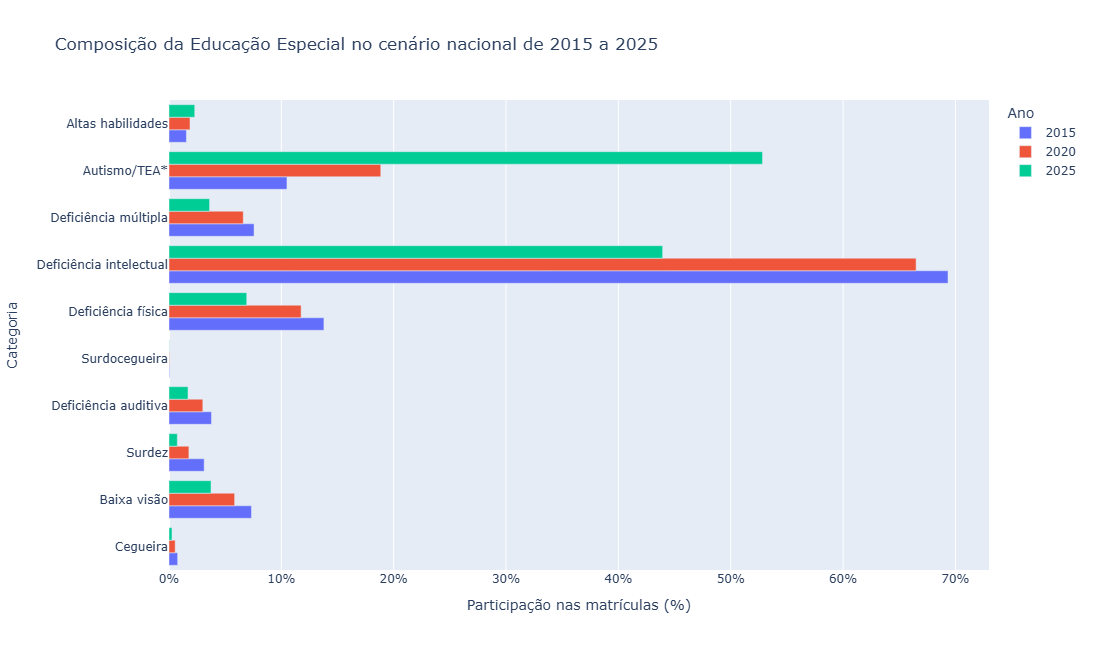

In [81]:
# Posições das categorias de deficiência nas tabelas
categorias_deficiencia = {
    "Cegueira": 5,
    "Baixa visão": 6,
    "Surdez": 7,
    "Deficiência auditiva": 8,
    "Surdocegueira": 9,
    "Deficiência física": 10,
    "Deficiência intelectual": 11,
    "Deficiência múltipla": 12}

# Monta a view nacional por categoria e ano
dados_2 = []

for ano, tabelas_ano in tabelas_2.items():
    linhas = [limpar_2(df) for df in tabelas_ano]
    total = sum(linha.iloc[4] for linha in linhas)

    categorias = {
        nome: [indice] for nome, indice in categorias_deficiencia.items()}
    categorias["Autismo/TEA*"] = [13, 14, 15, 16] if ano == 2015 else [13]
    categorias["Altas habilidades"] = [17] if ano == 2015 else [14]

    for categoria, indices in categorias.items():
        matriculas = sum(
            sum(linha.iloc[indice] for indice in indices)
            for linha in linhas
        )

        dados_2.append({
            "Ano": str(ano),
            "Categoria": categoria,
            "Matrículas": matriculas,
            "Percentual": round(matriculas / total * 100, 2)
        })

view_geral_2 = pd.DataFrame(dados_2)
display(view_geral_2)


# Gráfico de barras agrupadas para comparar os três anos
fig_2 = px.bar(
    view_geral_2,
    x="Percentual",
    y="Categoria",
    color="Ano",
    barmode="group",
    orientation="h",
    hover_data=["Matrículas"],
    title="Composição da Educação Especial no cenário nacional de 2015 a 2025",
    labels={"Percentual": "Participação nas matrículas (%)"}
)

fig_2.update_layout(height=650)
fig_2.update_xaxes(ticksuffix="%")
fig_2.show()


## 2.3) Leitura dos resultados

A partir da leitura dos dados, é possível observar como as diferentes categorias da Educação Especial estão representadas no cenário nacional e comparar suas participações entre os três anos .

É importante ressaltar que as porcentagens não representam grupos necessariamente distintos, uma vez que um mesmo aluno pode apresentar mais de uma condição. Além disso, as mudanças nas classificações utilizadas pelo INEP, principalmente em relação ao autismo/TEA, dificultam uma comparação direta entre todos os anos. Percebe-se que a composição de alunos com autismo ou TEA's aumentou ao longo dos anos no intervalo analisado, enquanto a proporção de alunos com deficiência intelectual diminuiu no passar dos anos. Após 2013, a comunidade científica já havia alertado por meio do DSM-5 das diferenças entre deficientes intelectuais e TEA's, mas, devido às burocracias brasileiras e às adoções da OMS (as quais o Brasil estava submetido no ano de 2015), muitos jovens pertecentes ao grupo dos TEA's eram classificados como deficientes intelectuais de forma errônea. É importante entender este cenário para que o 

*Os dados cobrem três anos específicos, não todos os anos entre 2015 e 2025.*

**Fontes:** [INEP — Sinopses Estatísticas da Educação Básica](https://www.gov.br/inep/pt-br/acesso-a-informacao/dados-abertos/sinopses-estatisticas/educacao-basica) // []()

## <font color = "iceblue"> PERGUNTA 3: <font color = "skyblue">Em que etapas de ensino estão esses alunos, e a presença deles diminui ao longo da trajetória escolar?

## 3.1) Limpeza e padronização dos dados

Assim como na questão 1, foi preciso limpar os dados e padronizá-los tendo em vista a formatação do arquivo. O arquivo está repleto de colunas sujeitas a hierarquia de colunas, dificultando o processamento dos dados. Portanto, fizemos uma função *limpar_3(df, indices)* para padronizar as colunas de totais. Outro detalhe importante de ser tratado é que nos 3 anos, as colunas de totais para cada etapa do ensino básico estão em posições numéricas distintas, fazendo-se necessária a declaração da lista de *posicoes* que contém as posições específicas das colunas que precisamos para fazer a comparação em percentuais. A função *limpar_3(df, indices)* é basicamente uma evolução da função *limpar_1(df)*, adicionando somente uma forma de sanar a incoerência nos índices posicionais das colunas das sinopses estatísticas de 2015, 2020 e 2025.

In [ ]:

etapas = ["Educação Infantil", "Ensino Fundamental", "Ensino Médio", "Educação Profissional"]

posicoes = {
    2015: ([5, 8, 11, 15], [5, 8, 11, 15]),
    2020: ([5, 8, 11, 15], [5, 8, 11, 15]),
    2025: ([5, 8, 11, 20], [7, 10, 13, 22])}


def limpar_3(df: pd.DataFrame, indices: list) -> pd.DataFrame:
    """Esta função seleciona exatamente as colunas de identificação regional, estadual e municipal e relaciona com as linhas de totais de 
    alunos em cada etapa do Ensino Básico brasileiro. 

    Parâmetros:
        df: pd.DataFrame - Tabela a ser padronizada e modificada
        indices: list - Posições das colunas usadas na tabela.
    Retornos:
        pd.DataFrame - Retorna um DataFrame contendo a tabela limpa com somente os totais de matrículas em cada etapa do ensino básico a cada
        ano, para cada região, estado e município.

    """
    df = df.iloc[:, [0, 1, 2, 3] + indices].copy()
    df.columns = ["Região", "Estado", "Município", "IBGE"] + etapas

    for etapa in etapas:
        df[etapa] = pd.to_numeric(df[etapa], errors="coerce")

    df["IBGE"] = pd.to_numeric(df["IBGE"], errors="coerce").astype("Int64")
    df = df[df[etapas].notna().any(axis=1)].copy()

    for coluna in ["Região", "Estado", "Município"]:
        df[coluna] = df[coluna].astype("string").str.strip().replace("", pd.NA)

    # Identifica corretamente as localidades
    df["id"] = "REG:" + df["Região"]
    df.loc[df["Estado"].notna(), "id"] = "UF:" + df["Estado"]
    df.loc[df["IBGE"].notna(), "id"] = "MUN:" + df["IBGE"].astype("string")

    return df.dropna(subset=["id"]).set_index("id")

## 3.2) Montagem dos DataFrames (*views*)



,Região,Estado,Município,IBGE,Educação Infantil_2015,Ensino Fundamental_2015,Ensino Médio_2015,Educação Profissional_2015,Educação Infantil_2020,Ensino Fundamental_2020,Ensino Médio_2020,Educação Profissional_2020,Educação Infantil_2025,Ensino Fundamental_2025,Ensino Médio_2025,Educação Profissional_2025
0,Brasil,<NA>,<NA>,<NA>,0.80,2.44,0.81,0.38,1.25,3.41,1.97,0.84,4.86,6.04,3.99,2.75
1,Norte,<NA>,<NA>,<NA>,0.75,1.94,0.61,0.59,1.26,3.02,1.70,1.18,5.60,5.56,3.61,2.90
2,Norte,Rondônia,<NA>,<NA>,1.12,2.74,1.08,0.79,1.49,3.76,2.39,1.47,6.29,6.69,4.59,3.44
3,Norte,Rondônia,Alta Floresta D'Oeste,1100015,0.93,2.16,0.59,NaN,1.08,2.51,1.61,NaN,5.94,5.17,2.94,3.52
4,Norte,Rondônia,Alto Alegre dos Parecis,1100379,0.56,2.41,1.02,NaN,1.56,3.17,0.74,NaN,4.55,5.16,4.88,2.70
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5599,Centro-Oeste,Goiás,Vicentinópolis,5222054,2.44,2.38,4.28,NaN,0.27,2.23,3.87,NaN,4.37,4.92,4.26,4.60
5600,Centro-Oeste,Goiás,Vila Boa,5222203,1.57,2.48,0.52,NaN,0.00,2.15,3.06,NaN,1.48,4.04,4.89,5.10
5601,Centro-Oeste,Goiás,Vila Propício,5222302,1.47,3.69,0.94,NaN,0.00,4.29,3.65,NaN,5.28,11.47,8.00,4.22
5602,Centro-Oeste,Distrito Federal,<NA>,<NA>,1.57,2.63,1.79,0.73,1.46,2.85,2.58,1.65,4.12,5.22,4.14,2.99


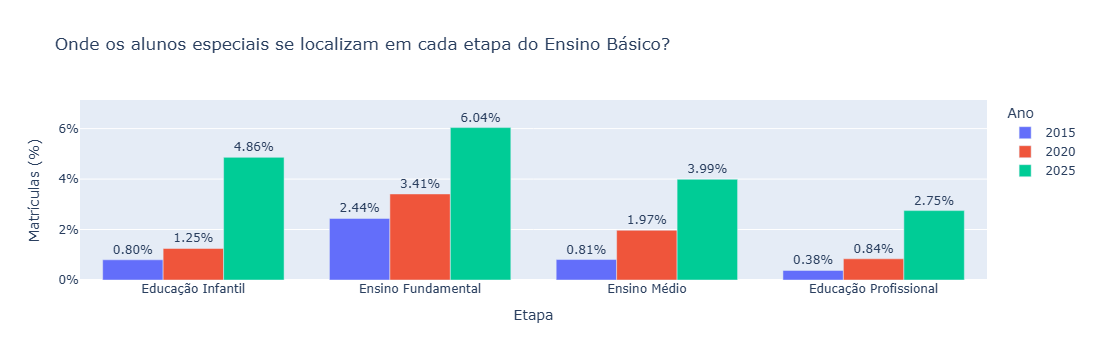

In [79]:
# Cria a view com as localidades de 2025
view_geral_3 = limpar_3(tb_11_2025, posicoes[2025][0])[["Região", "Estado", "Município", "IBGE"]].copy()


# Calcula as porcentagens por etapa e ano
for ano, (basica, especial) in tabelas.items():
    indices_basica, indices_especial = posicoes[ano]

    totais = limpar_3(basica, indices_basica)[etapas]
    esps = limpar_3(especial, indices_especial)[etapas]

    percentuais = (esps / totais.where(totais != 0) * 100).round(2)
    for etapa in etapas:
        view_geral_3[f"{etapa}_{ano}"] = percentuais[etapa]

display(view_geral_3.reset_index(drop=True))


# Gráfico de barras agrupadas para os 3 anos dados


view_brasil_3 = view_geral_3.loc["REG:Brasil"]

# Organiza os dados para o gráfico
dados = []

for ano in [2015, 2020, 2025]:
    for etapa in etapas:
        dados.append({"Ano": str(ano),
            "Etapa": etapa,
            "Percentual": view_brasil_3[f"{etapa}_{ano}"]})

view_pro_grafico = pd.DataFrame(dados)

# Cria o gráfico de barras
fig = px.bar(
    view_pro_grafico,
    x="Etapa",
    y="Percentual",
    color="Ano",
    barmode="group",
    text="Percentual",
    title="Onde os alunos especiais se localizam em cada etapa do Ensino Básico?",
    labels={"Percentual": "Matrículas (%)"})

fig.update_traces(texttemplate="%{y:.2f}%", textposition="outside")
fig.update_yaxes(ticksuffix="%")
fig.show()



## 3.3) Leitura dos resultados

A partir da leitura dos dados é possível visualizar que a quantidade de alunos especiais reside, em sua maioria, no Ensino Fundamental. Além disso, perceba que as porcentagens sofrem um brusco descrescimento após o Ensino Fundamental. É importante ressaltar que esta constatação não implica em conclusões sobre as capacidades de alunos especiais, mas apenas evidencia um momento do desenvolvimento acadêmico destes estudantes em que a maioria deles se encontra na atualidade.

*Os dados cobrem três anos específicos, não todos os anos entre 2015 e 2025.*

**Fonte:** [INEP — Sinopses Estatísticas da Educação Básica](https://www.gov.br/inep/pt-br/acesso-a-informacao/dados-abertos/sinopses-estatisticas/educacao-basica).

## <font color = "iceblue"> PERGUNTA 4: <font color = "skyblue">Qual a parcela desses alunos em classes comuns, e como ela difere entre rede pública e privada?

**Matrículas em classes comuns nas redes pública e privada** <br>
A comparação considera os anos de 2015, 2020 e 2025, com dados das Sinopses Estatísticas da Educação Básica do INEP.
A tabela reúne, para cada rede e ano, as matrículas em classes comuns e exclusivas. A rede pública inclui as dependências federal, estadual e municipal.

Em 2015 e 2020 foram usadas as tabelas 1.40 e 1.46 das Sinopses; em 2025, as tabelas 1.61 e 1.68.

In [2]:
# Cada linha do arquivo corresponde a uma rede em um dos três anos.
caminho = "pergunta4_dados_limpos_inep.csv"
dados = pd.read_csv(caminho, encoding="utf-8-sig")
dados["total_matriculas"] = dados["classes_comuns"] + dados["classes_exclusivas"]

# Conferimos se as duas redes somam o total nacional informado pelo INEP.
totais_por_ano = dados.groupby("ano")["total_matriculas"].sum()
assert totais_por_ano.to_dict() == {2015: 930683, 2020: 1308900, 2025: 2458159}
assert len(dados) == 6 and not dados.duplicated(["ano", "rede"]).any()

display(dados.sort_values(["ano", "rede"]).reset_index(drop=True))

,ano,rede,classes_comuns,classes_exclusivas,total_matriculas
0,2015,Privada,47364,131572,178936
1,2015,Pública,703619,48128,751747
2,2020,Privada,81101,117295,198396
3,2020,Pública,1071774,38730,1110504
4,2025,Privada,232753,119374,352127
5,2025,Pública,2065252,40780,2106032


## 4.1) Percentual em classes comuns

Para comparar as redes, dividimos as matrículas em classes comuns pelo total de matrículas da educação especial **dentro de cada rede**. Também calculamos a diferença entre os percentuais, em pontos percentuais.

In [3]:
# Percentual de matrículas em classes comuns em cada rede.
dados["percentual_comuns"] = (
    dados["classes_comuns"] / dados["total_matriculas"] * 100
)

comparacao = dados.pivot(
    index="ano", columns="rede", values="percentual_comuns"
).sort_index()

comparacao["Diferença (p.p.)"] = comparacao["Pública"] - comparacao["Privada"]

display(comparacao.round(2))

rede,Privada,Pública,Diferença (p.p.)
ano,,,
2015,26.47,93.60,67.13
2020,40.88,96.51,55.63
2025,66.10,98.06,31.96


## 4.2) Evolução por rede

O gráfico mostra o percentual de matrículas em classes comuns nas duas redes. Cada ponto corresponde a um ano disponível na base; as linhas apenas ligam esses valores.

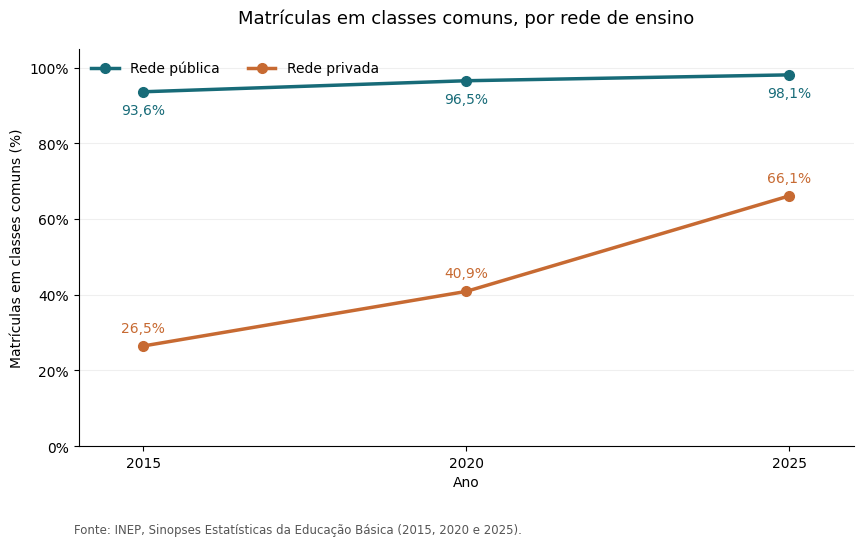

In [4]:
anos = [2015, 2020, 2025]
cores = {"Pública": "#176B78", "Privada": "#C76A32"}

figura, eixo = plt.subplots(figsize=(10, 5.6))

for rede in ["Pública", "Privada"]:
    dados_rede = dados[dados["rede"] == rede].sort_values("ano")

    eixo.plot(
        dados_rede["ano"], dados_rede["percentual_comuns"],
        marker="o", markersize=7, linewidth=2.5,
        color=cores[rede], label=f"Rede {rede.lower()}"
    )

    # Os valores ao lado dos pontos facilitam a leitura dos três anos.
    for _, linha in dados_rede.iterrows():
        deslocamento = -16 if rede == "Pública" else 10
        eixo.annotate(
            f'{linha["percentual_comuns"]:.1f}%'.replace(".", ","),
            (linha["ano"], linha["percentual_comuns"]),
            xytext=(0, deslocamento), textcoords="offset points",
            ha="center", fontsize=10, color=cores[rede]
        )

eixo.set_title("Matrículas em classes comuns, por rede de ensino", fontsize=13, pad=18)
eixo.set_xlabel("Ano")
eixo.set_ylabel("Matrículas em classes comuns (%)")
eixo.set_xticks(anos)
eixo.set_xlim(2014, 2026)
eixo.set_ylim(0, 105)
eixo.set_yticks(range(0, 101, 20))
eixo.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: f"{valor:.0f}%"))
eixo.grid(axis="y", alpha=0.2)
eixo.set_axisbelow(True)
eixo.spines[["top", "right"]].set_visible(False)
eixo.legend(loc="upper left", frameon=False, ncol=2)

figura.text(
    0.12, 0.015,
    "Fonte: INEP, Sinopses Estatísticas da Educação Básica (2015, 2020 e 2025).",
    fontsize=8.5, color="#555555"
)
figura.subplots_adjust(bottom=0.17, top=0.88)
plt.savefig("pergunta4_grafico_redes.png", dpi=180, bbox_inches="tight")
plt.show()

## 4.3) Leitura dos resultados

A parcela de matrículas em classes comuns aumentou nas duas redes. Na **rede pública**, passou de **93,6% em 2015 para 98,1% em 2025**. Na **rede privada**, foi de **26,5% para 66,1%** no mesmo período.

A diferença entre as redes caiu de **67,1 para 32,0 pontos percentuais**. Mesmo assim, o percentual da rede privada continuou menor em 2025.

Esses números mostram onde os alunos estão matriculados, mas não indicam, por si só, a qualidade do atendimento. A rede privada também inclui instituições que oferecem ensino em classes exclusivas.

*Os dados cobrem três anos específicos, não todos os anos entre 2015 e 2025.*

**Fonte:** [INEP — Sinopses Estatísticas da Educação Básica](https://www.gov.br/inep/pt-br/acesso-a-informacao/dados-abertos/sinopses-estatisticas/educacao-basica).

## <font color = "iceblue"> PERGUNTA 5: <font color = "skyblue">O crescimento e a inclusão vistos no país se repetem em todas as regiões e estados, ou a média nacional é puxada por poucos estados?

**Educação especial no Brasil**

A análise usa as Sinopses Estatísticas da Educação Básica do INEP de **2015, 2020 e 2025**. Primeiro, comparamos a inclusão nas cinco regiões com o Brasil. Depois, analisamos a contribuição de cada estado para o aumento do número de matrículas.

**Fonte:** INEP, *Sinopses Estatísticas da Educação Básica* (2015, 2020 e 2025).

In [5]:
# Carregamos a planilha usada na pergunta 5.
arquivo = "base_limpa_pergunta5_inep_2015_2020_2025.xlsx"
dados = pd.read_excel(arquivo, sheet_name="Base limpa", header=3)

# Confere cada coluna a cada ano procurando pelas numerações de matriculas totais, classes comuns e classes exclusivas.
dados['ano'] = dados['ano'].astype(int)
for coluna in ['matriculas_total', 'matriculas_classes_comuns', 'matriculas_classes_exclusivas']:
    dados[coluna] = pd.to_numeric(dados[coluna])

# Calculamos a inclusão a partir do número de matrículas, sem usar porcentagens prontas.
dados['inclusao_pct'] = 100 * dados['matriculas_classes_comuns'] / dados['matriculas_total']
estados = dados[dados['nivel'] == 'UF'].copy()
brasil = dados[dados['nivel'] == 'Brasil'].copy().sort_values('ano')

# Conferimos as 27 UFs e os totais divulgados para o Brasil.
assert len(estados) == 81 and len(brasil) == 3
assert estados.groupby('ano')['uf'].nunique().eq(27).all()
assert (dados['matriculas_classes_comuns'] + dados['matriculas_classes_exclusivas'] == dados['matriculas_total']).all()
assert (estados.groupby('ano')['matriculas_total'].sum().sort_index().to_numpy() == brasil['matriculas_total'].to_numpy()).all()

print('Dados conferidos: 27 estados e três anos.')
display(brasil[['ano', 'matriculas_total', 'inclusao_pct']].round(2).reset_index(drop=True))

Dados conferidos: 27 estados e três anos.


,ano,matriculas_total,inclusao_pct
0,2015,930683,80.69
1,2020,1308900,88.08
2,2025,2458159,93.48


## 5.1) Inclusão em classes comuns por região

O gráfico reúne as **cinco regiões brasileiras** e a linha nacional. Para cada região, calculamos o percentual a partir da soma das matrículas em classes comuns dividida pelo total de matrículas da educação especial na região. Assim, cada estado participa conforme o número de matrículas que possui; não usamos uma média simples dos percentuais estaduais.

A comparação considera três anos: **2015, 2020 e 2025**. As linhas ligam esses pontos, sem estimar os anos intermediários.

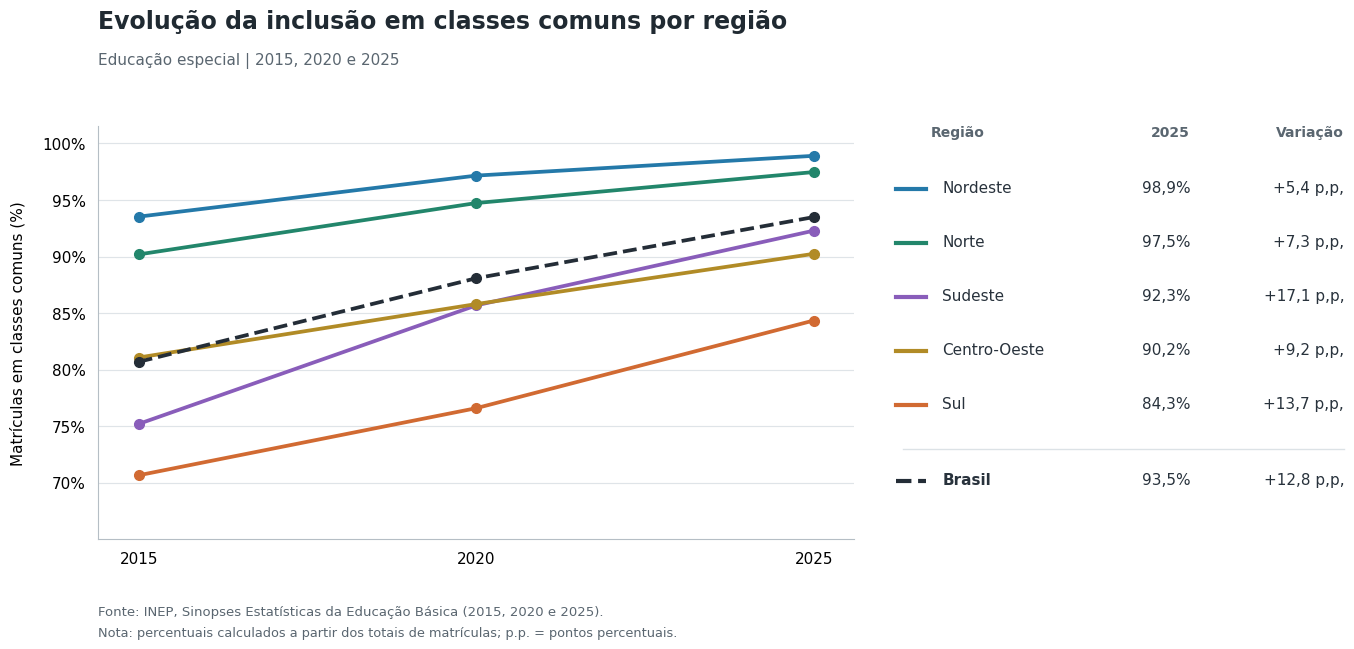

In [6]:
# Somamos as matrículas por região antes de calcular o percentual de inclusão.
resumo_regioes = (
    estados.groupby(['regiao', 'ano'], as_index=False)[
        ['matriculas_total', 'matriculas_classes_comuns']
    ].sum()
)
resumo_regioes['inclusao_pct'] = (
    100 * resumo_regioes['matriculas_classes_comuns']
    / resumo_regioes['matriculas_total']
)

anos = [2015, 2020, 2025]
cores = {
    'Norte': '#22866B',
    'Nordeste': '#2479A9',
    'Sudeste': '#895DBA',
    'Sul': '#D16A32',
    'Centro-Oeste': '#B18B26',
    'Brasil': '#242D37'
}

figura, grafico = plt.subplots(figsize=(14, 7))
figura.subplots_adjust(left=0.09, right=0.63, top=0.78, bottom=0.19)

# Uma única linha por região facilita a comparação da mudança ao longo do tempo.
ordem = ['Nordeste', 'Norte', 'Sudeste', 'Centro-Oeste', 'Sul']
for regiao in ordem:
    serie = resumo_regioes[resumo_regioes['regiao'] == regiao].sort_values('ano')
    grafico.plot(
        serie['ano'], serie['inclusao_pct'],
        color=cores[regiao], marker='o', markersize=7,
        linewidth=2.7, label=regiao
    )

# O Brasil funciona como referência; é o percentual nacional calculado pelo total de matrículas.
grafico.plot(
    brasil['ano'], brasil['inclusao_pct'],
    color=cores['Brasil'], linestyle='--',
    marker='o', markersize=7, linewidth=2.7, label='Brasil'
)

grafico.set_xlim(2014.4, 2025.6)
grafico.set_ylim(65, 101.5)
grafico.set_xticks(anos)
grafico.set_yticks([70, 75, 80, 85, 90, 95, 100])
grafico.set_yticklabels(['70%', '75%', '80%', '85%', '90%', '95%', '100%'])
grafico.grid(axis='y', color='#dfe4e8', linewidth=0.85)
grafico.set_axisbelow(True)
grafico.spines[['top', 'right']].set_visible(False)
grafico.spines[['left', 'bottom']].set_color('#b5bec5')
grafico.tick_params(axis='both', labelsize=11, length=0, pad=9)
grafico.set_ylabel('Matrículas em classes comuns (%)', fontsize=11, labelpad=12)

figura.text(0.09, 0.92, 'Evolução da inclusão em classes comuns por região',
            fontsize=17, weight='bold', color='#202a32')
figura.text(0.09, 0.868, 'Educação especial | 2015, 2020 e 2025',
            fontsize=11, color='#5a6670')

# Resumo lateral: valor de 2025 e variação desde 2015, em pontos percentuais.
figura.text(0.685, 0.765, 'Região', fontsize=10, color='#5a6670', weight='bold')
figura.text(0.87, 0.765, '2025', fontsize=10, color='#5a6670', weight='bold', ha='right')
figura.text(0.98, 0.765, 'Variação', fontsize=10, color='#5a6670', weight='bold', ha='right')

def escrever_resumo(nome, valores, altura):
    valor_2015 = valores.loc[2015]
    valor_2025 = valores.loc[2025]
    aumento = valor_2025 - valor_2015
    linha = '--' if nome == 'Brasil' else '-'
    figura.lines.append(plt.Line2D([0.66, 0.681], [altura + 0.005, altura + 0.005],
                                   color=cores[nome], linewidth=3,
                                   linestyle=linha, transform=figura.transFigure))
    figura.text(0.693, altura, nome, fontsize=11, color='#28323c',
                weight='bold' if nome == 'Brasil' else 'normal')
    figura.text(0.87, altura, f'{valor_2025:.1f}%'.replace('.', ','),
                fontsize=11, ha='right', color='#28323c')
    figura.text(0.98, altura, f'+{aumento:.1f} p.p.'.replace('.', ','),
                fontsize=11, ha='right', color='#28323c')

for regiao, altura in zip(ordem, [0.685, 0.608, 0.531, 0.454, 0.377]):
    percentual = resumo_regioes[resumo_regioes['regiao'] == regiao].set_index('ano')['inclusao_pct']
    escrever_resumo(regiao, percentual, altura)

figura.lines.append(plt.Line2D([0.665, 0.98], [0.319, 0.319],
                               color='#dce2e6', linewidth=1,
                               transform=figura.transFigure))
escrever_resumo('Brasil', brasil.set_index('ano')['inclusao_pct'], 0.268)

figura.text(0.09, 0.082,
            'Fonte: INEP, Sinopses Estatísticas da Educação Básica (2015, 2020 e 2025).',
            fontsize=9.5, color='#5a6670')
figura.text(0.09, 0.052,
            'Nota: percentuais calculados a partir dos totais de matrículas; p.p. = pontos percentuais.',
            fontsize=9.3, color='#5a6670')

plt.savefig('inclusao_por_regiao.png', dpi=190, bbox_inches='tight', facecolor='white')
plt.show()

## 5.2) Quais estados mais contribuíram para o aumento das matrículas?

Aqui comparamos o **número de matrículas** de 2015 e 2025. A contribuição de cada estado é sua parte no aumento total do Brasil. Isso não é a mesma coisa que a taxa de crescimento estadual.

,uf,matriculas_2015,matriculas_2020,matriculas_2025,aumento_matriculas,contribuicao_pct
0,São Paulo,167251,213061,373454,206203,13.50
1,Bahia,62645,102286,219850,157205,10.29
2,Ceará,41341,66741,160556,119215,7.80
3,Minas Gerais,111014,145607,227069,116055,7.60
4,Rio de Janeiro,54562,79329,154308,99746,6.53
5,Paraná,81345,104280,165666,84321,5.52
6,Pernambuco,31207,48573,112445,81238,5.32
7,Pará,31601,52779,104842,73241,4.79
8,Santa Catarina,27438,40913,98708,71270,4.67
9,Rio Grande do Sul,76402,96106,143069,66667,4.36


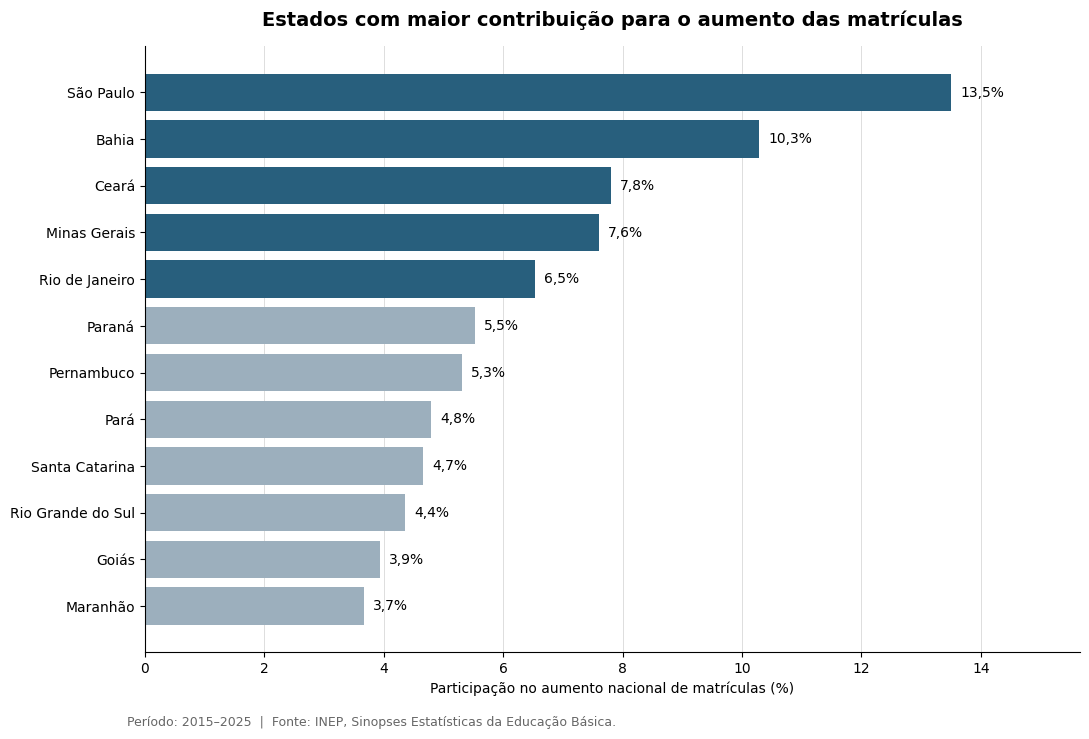

In [7]:
# Juntamos os três anos em uma linha para cada estado.
comparacao = estados.pivot(index=['regiao', 'uf'], columns='ano', values='matriculas_total').reset_index()
comparacao.columns.name = None
comparacao = comparacao.rename(columns={
    2015: 'matriculas_2015',
    2020: 'matriculas_2020',
    2025: 'matriculas_2025'
})

comparacao['aumento_matriculas'] = comparacao['matriculas_2025'] - comparacao['matriculas_2015']
comparacao['crescimento_pct'] = 100 * comparacao['aumento_matriculas'] / comparacao['matriculas_2015']

matriculas_brasil = brasil.set_index('ano')['matriculas_total']
aumento_brasil = matriculas_brasil.loc[2025] - matriculas_brasil.loc[2015]

# As contribuições dos 27 estados devem somar 100%.
comparacao['contribuicao_pct'] = 100 * comparacao['aumento_matriculas'] / aumento_brasil
comparacao = comparacao.sort_values('contribuicao_pct', ascending=False)
assert comparacao['aumento_matriculas'].sum() == aumento_brasil
assert abs(comparacao['contribuicao_pct'].sum() - 100) < 1e-8

colunas_resumo = ['uf', 'matriculas_2015', 'matriculas_2020',
                  'matriculas_2025', 'aumento_matriculas', 'contribuicao_pct']
display(comparacao[colunas_resumo].head(12).round(2).reset_index(drop=True))

principais_estados = comparacao.head(12).sort_values('contribuicao_pct')
destaques = set(comparacao.head(5)['uf'])
cores_barras = ['#285f7d' if nome in destaques else '#9cafbd'
                for nome in principais_estados['uf']]

figura, grafico = plt.subplots(figsize=(11, 7.5))
grafico.barh(principais_estados['uf'], principais_estados['contribuicao_pct'], color=cores_barras)

for posicao, valor in enumerate(principais_estados['contribuicao_pct']):
    grafico.text(valor + 0.15, posicao, f'{valor:.1f}%'.replace('.', ','),
                 va='center', fontsize=10)

grafico.set_xlim(0, principais_estados['contribuicao_pct'].max() * 1.16)
grafico.set_title('Estados com maior contribuição para o aumento das matrículas',
                   fontsize=14, fontweight='bold', pad=15)
grafico.set_xlabel('Participação no aumento nacional de matrículas (%)')
grafico.grid(axis='x', color='#dddddd', linewidth=0.7)
grafico.set_axisbelow(True)
grafico.spines[['top', 'right']].set_visible(False)
figura.text(0.12, 0.025, 'Período: 2015–2025  |  Fonte: INEP, Sinopses Estatísticas da Educação Básica.',
            fontsize=9, color='#666666')
figura.tight_layout(rect=[0, 0.045, 1, 1])

plt.savefig('contribuicao_estadual.png', dpi=180, bbox_inches='tight')
plt.show()

## 5.3) Leitura dos resultados

A proporção de matrículas em classes comuns aumentou em **todas as regiões** entre 2015 e 2025. O **Nordeste** já tinha um percentual alto em 2015 (93,5%) e chegou a **98,9%** em 2025. O **Sudeste** apresentou o maior avanço, passando de **75,2% para 92,3%**. O **Sul** também cresceu, mas terminou o período com **84,3%**, abaixo do Brasil (**93,5%**).

O número de matrículas da educação especial no país passou de **930,7 mil para 2,46 milhões**. No segundo gráfico, **São Paulo, Bahia, Ceará, Minas Gerais e Rio de Janeiro** foram os cinco estados que mais contribuíram para esse aumento, somando cerca de **45,7%** do crescimento nacional.

Os gráficos mostram aspectos diferentes: o primeiro compara o percentual de matrículas em classes comuns, enquanto o segundo mostra onde ocorreu o maior aumento no número de matrículas. **Os dados não medem a qualidade do atendimento.** Além disso, com três anos observados não é possível descrever todas as mudanças que ocorreram entre eles.

## <font color = "iceblue"> PERGUNTA 6: <font color = "skyblue">Como o peso da educação especial nas matrículas varia entre os estados, e ele acompanha a proporção de pessoas com deficiência e autismo medida pelo IBGE?

## 6.1) Educação especial por estado

**Como o peso da educação especial nas matrículas varia entre os estados, e ele acompanha a proporção de pessoas com deficiência e autismo medida pelo IBGE?**

**Recorte:** 27 UFs; matrículas do INEP de **2025** e população do Censo IBGE de **2022**. Deficiência considera pessoas de 2 anos ou mais; autismo, todas as idades. Os percentuais populacionais são resultados preliminares, arredondados a uma casa decimal.

In [9]:
# Base já tratada: INEP e IBGE reunidos pelo código da UF.
# Os dados estão incluídos no notebook para permitir sua execução independente.
csv_dados = """
codigo_uf,sigla,uf,regiao,matriculas_basica,matriculas_especial,deficiencia_pct,autismo_pct
11,RO,Rondônia,Norte,376264,22898,7.1,1.3
12,AC,Acre,Norte,242727,23739,7.3,1.6
13,AM,Amazonas,Norte,1131739,44033,7.0,1.1
14,RR,Roraima,Norte,186395,8546,5.6,1.2
15,PA,Pará,Norte,2146239,104842,7.3,1.1
16,AP,Amapá,Norte,212026,15602,7.1,1.5
17,TO,Tocantins,Norte,380768,20047,6.9,1.0
21,MA,Maranhão,Nordeste,1821863,86566,8.1,1.1
22,PI,Piauí,Nordeste,823199,49014,9.3,1.2
23,CE,Ceará,Nordeste,2108135,160556,8.9,1.4
24,RN,Rio Grande do Norte,Nordeste,756434,44748,8.8,1.1
25,PB,Paraíba,Nordeste,942549,58813,8.6,1.2
26,PE,Pernambuco,Nordeste,2076655,112445,8.9,1.2
27,AL,Alagoas,Nordeste,831546,43876,9.6,1.1
28,SE,Sergipe,Nordeste,520379,30646,8.6,1.2
29,BA,Bahia,Nordeste,3345058,219850,7.9,1.0
31,MG,Minas Gerais,Sudeste,4220829,227069,7.3,1.1
32,ES,Espírito Santo,Sudeste,867017,59098,7.2,1.3
33,RJ,Rio de Janeiro,Sudeste,3319771,154308,7.4,1.3
35,SP,São Paulo,Sudeste,9600318,373454,6.3,1.2
41,PR,Paraná,Sul,2438428,165666,6.4,1.2
42,SC,Santa Catarina,Sul,1769938,98708,6.0,1.2
43,RS,Rio Grande do Sul,Sul,2189268,143069,7.2,1.1
50,MS,Mato Grosso do Sul,Centro-Oeste,675479,33361,6.5,1.1
51,MT,Mato Grosso,Centro-Oeste,888828,40550,5.7,1.1
52,GO,Goiás,Centro-Oeste,1526256,87001,7.0,1.1
53,DF,Distrito Federal,Centro-Oeste,620272,29654,6.1,1.2
"""

dados = pd.read_csv(StringIO(csv_dados))

## 6.2) Indicadores

$$
\text{Participação da educação especial (\%)} =
\frac{\text{matrículas da educação especial}}{\text{matrículas da educação básica}}\times 100
$$

O percentual nacional usa a soma das matrículas. A associação com os indicadores do IBGE é medida pela **correlação de Pearson**, com o mesmo peso para cada UF; valores positivos indicam associação linear crescente.

In [10]:
# Conferimos a cobertura e os totais nacionais antes de calcular os indicadores.
assert len(dados) == 27 and dados['codigo_uf'].is_unique
assert not dados.isna().any().any()
assert dados['matriculas_basica'].sum() == 46018380
assert dados['matriculas_especial'].sum() == 2458159

# Participação da educação especial em cada UF e no Brasil.
dados['educacao_especial_pct'] = 100 * dados['matriculas_especial'] / dados['matriculas_basica']
percentual_brasil = 100 * dados['matriculas_especial'].sum() / dados['matriculas_basica'].sum()

# As duas correlações usam as 27 UFs e os valores sem arredondamento adicional.
r_deficiencia = dados['educacao_especial_pct'].corr(dados['deficiencia_pct'])
r_autismo = dados['educacao_especial_pct'].corr(dados['autismo_pct'])

# Verificação complementar da influência do Acre; a análise principal mantém essa UF.
sem_acre = dados[dados['sigla'] != 'AC']
r_autismo_sem_acre = sem_acre['educacao_especial_pct'].corr(sem_acre['autismo_pct'])

# A mesma cor identifica cada região nos três gráficos.
cores = {'Norte': '#087F8C', 'Nordeste': '#C5633A', 'Sudeste': '#386CB0',
         'Sul': '#8B61A8', 'Centro-Oeste': '#9A7820'}
dados['cor'] = dados['regiao'].map(cores)
ranking = dados.sort_values('educacao_especial_pct', ascending=False).reset_index(drop=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11})

## 6.3) Participação da educação especial nas matrículas

Cada ponto representa uma UF. A linha tracejada indica o percentual nacional.

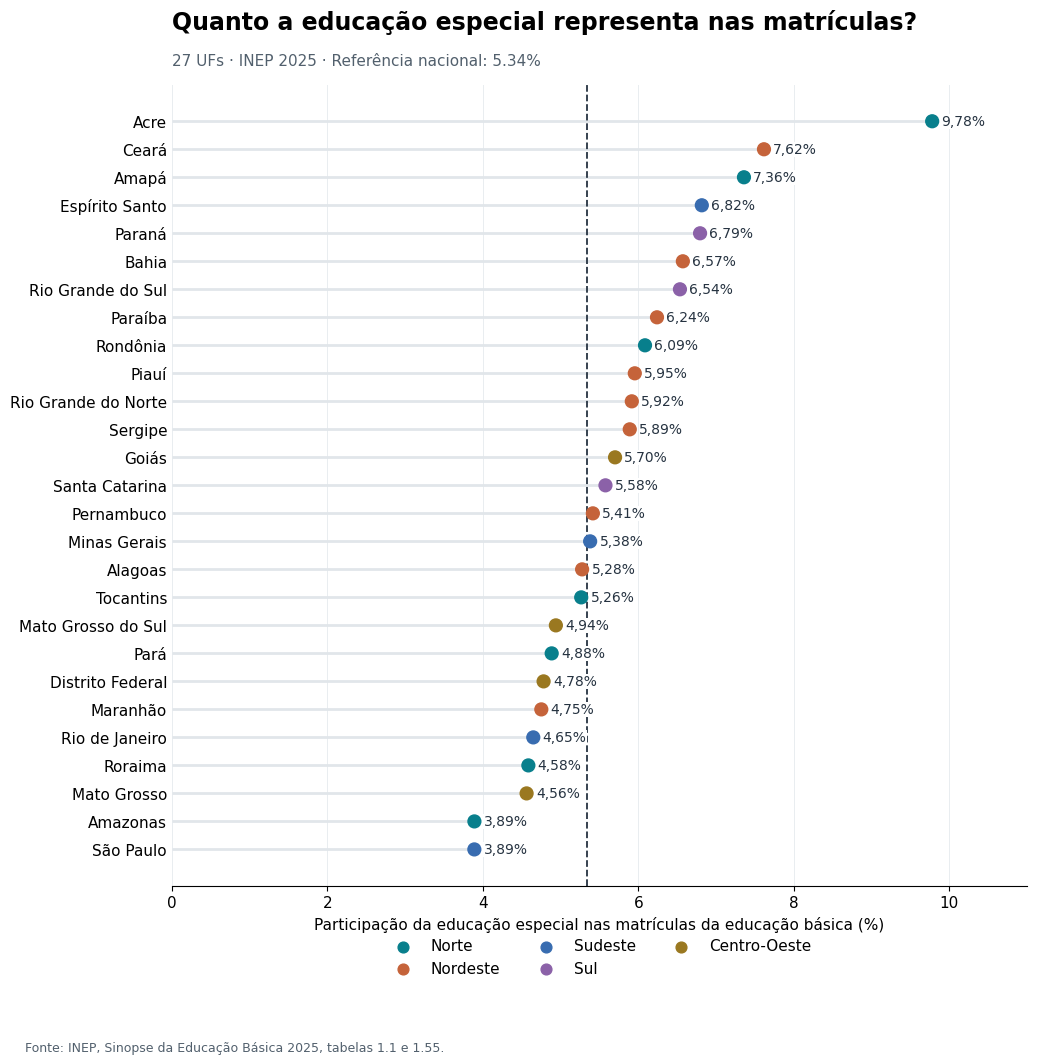

In [11]:
fig_ranking, ax = plt.subplots(figsize=(10.5, 11))

# Ordenação das UFs e referência nacional.
ax.hlines(y=ranking['uf'], xmin=0, xmax=ranking['educacao_especial_pct'],
          color='#E1E6EA', linewidth=2)
ax.scatter(ranking['educacao_especial_pct'], ranking['uf'],
           c=ranking['cor'], s=85, zorder=3)

ax.invert_yaxis()
ax.axvline(percentual_brasil, color='#263341', linestyle='--', linewidth=1.3)

# Valores ao lado dos pontos.
for _, linha in ranking.iterrows():
    rotulo = f"{linha['educacao_especial_pct']:.2f}%".replace('.', ',')
    ax.text(linha['educacao_especial_pct'] + 0.12, linha['uf'], rotulo,
            va='center', fontsize=10, color='#263341',
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 0.4})

ax.set_xlim(0, 11)
ax.set_xlabel('Participação da educação especial nas matrículas da educação básica (%)')
ax.set_title('Quanto a educação especial representa nas matrículas?',
             loc='left', fontsize=17, fontweight='bold', pad=40)
ax.text(0, 1.025, f'27 UFs · INEP 2025 · Referência nacional: {percentual_brasil:.2f}%',
        transform=ax.transAxes, color='#52606D', fontsize=11)
ax.grid(axis='x', color='#E9EDF0', linewidth=0.7)
ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(axis='y', length=0)

# Legenda por região.
for regiao, cor in cores.items():
    ax.scatter([], [], color=cor, s=60, label=regiao)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=False)
fig_ranking.text(0.03, 0.018, 'Fonte: INEP, Sinopse da Educação Básica 2025, tabelas 1.1 e 1.55.',
                 color='#52606D', fontsize=9)
fig_ranking.tight_layout(rect=[0, 0.06, 1, 0.98])
plt.show()

## 6.4) Associação com a proporção de pessoas com deficiência

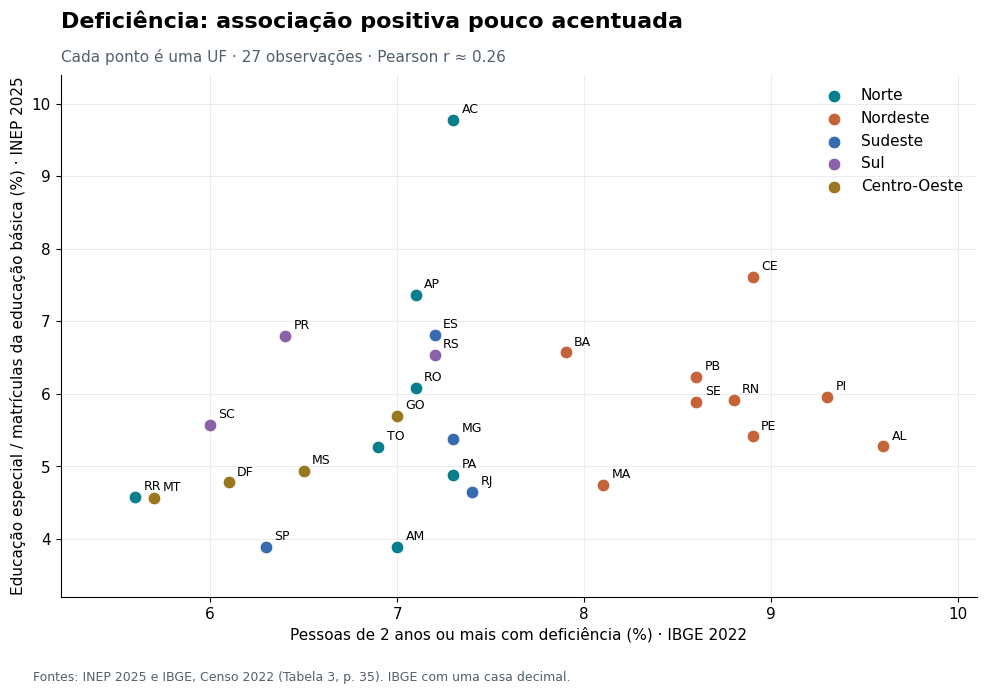

In [12]:
fig_deficiencia, ax = plt.subplots(figsize=(10, 7.2))

# Cada ponto é uma UF; as cores identificam as regiões.
for regiao, cor in cores.items():
    grupo = dados[dados['regiao'] == regiao]
    ax.scatter(grupo['deficiencia_pct'], grupo['educacao_especial_pct'],
               color=cor, s=85, edgecolor='white', linewidth=0.7, label=regiao)

# Identificação das UFs pelas siglas.
for _, linha in dados.iterrows():
    ax.annotate(linha['sigla'],
                (linha['deficiencia_pct'], linha['educacao_especial_pct']),
                xytext=(6, 5), textcoords='offset points', fontsize=9)

ax.set_xlim(5.2, 10.1)
ax.set_ylim(3.2, 10.4)
ax.set_xlabel('Pessoas de 2 anos ou mais com deficiência (%) · IBGE 2022')
ax.set_ylabel('Educação especial / matrículas da educação básica (%) · INEP 2025')
ax.set_title('Deficiência: associação positiva pouco acentuada',
             loc='left', fontsize=16, fontweight='bold', pad=34)
ax.text(0, 1.025, f'Cada ponto é uma UF · 27 observações · Pearson r ≈ {r_deficiencia:.2f}',
        transform=ax.transAxes, fontsize=11, color='#52606D')
ax.grid(color='#E9EDF0', linewidth=0.7)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(loc='upper right', frameon=False)
fig_deficiencia.text(0.04, 0.025, 'Fontes: INEP 2025 e IBGE, Censo 2022 (Tabela 3, p. 35). IBGE com uma casa decimal.',
                     fontsize=9, color='#52606D')
fig_deficiencia.tight_layout(rect=[0, 0.055, 1, 0.98])
plt.show()

## 6.5) Associação com a proporção de pessoas com diagnóstico de autismo

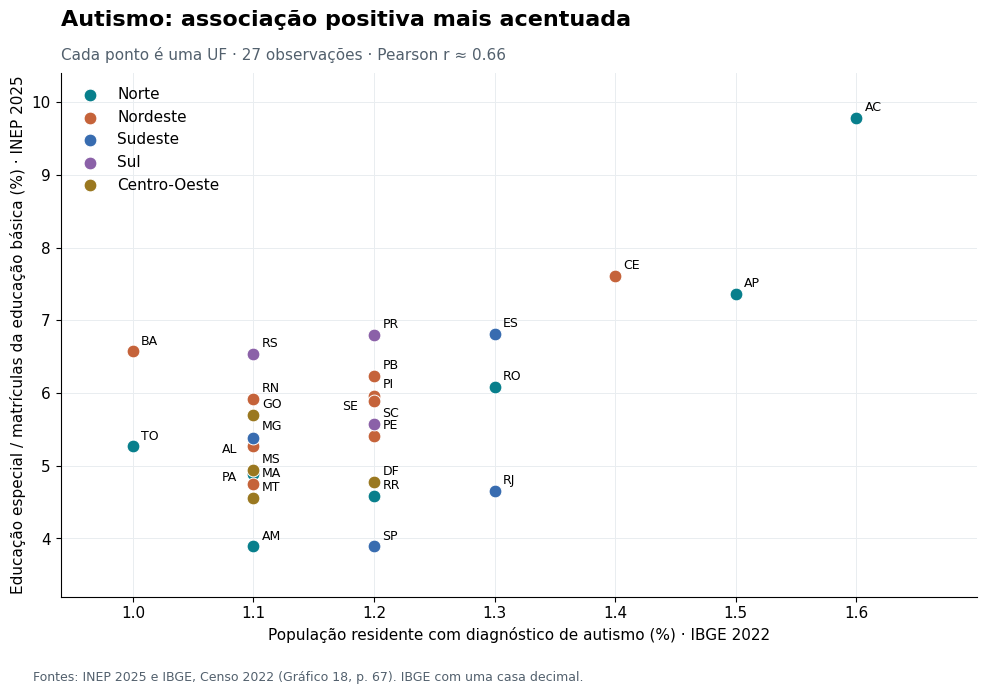

In [13]:
fig_autismo, ax = plt.subplots(figsize=(10, 7.2))

for regiao, cor in cores.items():
    grupo = dados[dados['regiao'] == regiao]
    ax.scatter(grupo['autismo_pct'], grupo['educacao_especial_pct'],
               color=cor, s=85, edgecolor='white', linewidth=0.7, label=regiao)

# Ajustamos apenas os rótulos próximos, preservando a posição dos dados.
ajustes = {'AL': (-23, -5), 'PA': (-23, -5), 'SE': (-23, -6),
           'PI': (6, 6), 'MG': (6, 6), 'MS': (6, 5)}
for _, linha in dados.iterrows():
    deslocamento = ajustes.get(linha['sigla'], (6, 5))
    ax.annotate(linha['sigla'],
                (linha['autismo_pct'], linha['educacao_especial_pct']),
                xytext=deslocamento, textcoords='offset points', fontsize=9)

ax.set_xlim(0.94, 1.70)
ax.set_ylim(3.2, 10.4)
ax.set_xticks([1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6])
ax.set_xlabel('População residente com diagnóstico de autismo (%) · IBGE 2022')
ax.set_ylabel('Educação especial / matrículas da educação básica (%) · INEP 2025')
ax.set_title('Autismo: associação positiva mais acentuada',
             loc='left', fontsize=16, fontweight='bold', pad=34)
ax.text(0, 1.025, f'Cada ponto é uma UF · 27 observações · Pearson r ≈ {r_autismo:.2f}',
        transform=ax.transAxes, fontsize=11, color='#52606D')
ax.grid(color='#E9EDF0', linewidth=0.7)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(loc='upper left', frameon=False)
fig_autismo.text(0.04, 0.025, 'Fontes: INEP 2025 e IBGE, Censo 2022 (Gráfico 18, p. 67). IBGE com uma casa decimal.',
                 fontsize=9, color='#52606D')
fig_autismo.tight_layout(rect=[0, 0.055, 1, 0.98])
plt.show()

## 6.6) Leitura dos resultados

- A participação da educação especial varia de **3,89% em São Paulo a 9,78% no Acre**, com **5,34% no Brasil**. Amazonas também apresenta 3,89% após arredondamento.
- A associação linear é positiva e pequena para **deficiência (r ≈ 0,26)**, e mais acentuada para **diagnóstico de autismo (r ≈ 0,66)**.
- O Acre influencia a segunda relação: sem essa UF, **r ≈ 0,46**. O indicador de autismo acompanha parcialmente a variação entre UFs, mas não descreve toda a diferença nas matrículas.

**Limites:** os anos e os públicos das bases são diferentes; matrículas não são pessoas únicas. Os coeficientes são aproximados devido ao arredondamento do IBGE. A comparação não mede cobertura ou qualidade do atendimento, e associação não demonstra causalidade.

**Fontes:** [INEP — Sinopse da Educação Básica 2025](https://www.gov.br/inep/pt-br/acesso-a-informacao/dados-abertos/sinopses-estatisticas/educacao-basica), tabelas 1.1 e 1.55, totais por UF; [IBGE — Censo Demográfico 2022](https://www.ibge.gov.br/biblioteca/visualizacao/livros/liv102178.pdf), *Pessoas com deficiência e pessoas diagnosticadas com transtorno do espectro autista*, Tabela 3 (p. 35) e Gráfico 18 (p. 67). [Cópia da publicação consultada](https://dados.dataverso.org/wp-content/uploads/sites/9/tainacan-items/122/1230/liv102178.pdf).

## <font color = "iceblue"> PERGUNTA 7: <font color = "skyblue">Os estados onde a educação especial mais cresceu são os que mais ampliaram a inclusão em classes comuns?

## 7.1) Crescimento e inclusão na educação especial

**Os estados onde a educação especial mais cresceu são os que mais ampliaram a inclusão em classes comuns?**

Comparamos as **27 UFs entre 2015 e 2025**. Primeiro, observamos a relação geral; depois, comparamos os estados individualmente. Inclusão é a parcela das matrículas da educação especial em classes comuns, não uma medida da qualidade do atendimento.

In [15]:
# Base por UF extraída das Sinopses do INEP e conferida com a análise original.
# total = classes comuns + classes exclusivas. Dados incluídos para rodar sem downloads.
csv_dados = """
sigla,uf,regiao,total_2015,comuns_2015,total_2020,comuns_2020,total_2025,comuns_2025
AC,Acre,Norte,7402,7402,11961,11961,23739,23439
AP,Amapá,Norte,4437,3910,6381,6222,15602,15223
AM,Amazonas,Norte,11739,9243,20939,18010,44033,41844
PA,Pará,Norte,31601,30898,52779,52436,104842,104244
RO,Rondônia,Norte,10669,8853,12920,12221,22898,22451
RR,Roraima,Norte,2190,2190,3588,3588,8546,8471
TO,Tocantins,Norte,11491,9228,15504,13090,20047,17957
AL,Alagoas,Nordeste,15704,15616,23957,23843,43876,43721
BA,Bahia,Nordeste,62645,59045,102286,99774,219850,217291
CE,Ceará,Nordeste,41341,39761,66741,65585,160556,159285
MA,Maranhão,Nordeste,30607,26634,44146,41059,86566,84775
PB,Paraíba,Nordeste,16671,15918,25140,24656,58813,57737
PE,Pernambuco,Nordeste,31207,26927,48573,46095,112445,111432
PI,Piauí,Nordeste,13133,12903,22412,22198,49014,48572
RN,Rio Grande do Norte,Nordeste,15268,15263,21458,21457,44748,44635
SE,Sergipe,Nordeste,7341,6700,11178,10803,30646,30189
ES,Espírito Santo,Sudeste,19035,19015,31952,31952,59098,58973
MG,Minas Gerais,Sudeste,111014,77120,145607,122806,227069,209596
RJ,Rio de Janeiro,Sudeste,54562,42000,79329,69061,154308,144524
SP,São Paulo,Sudeste,167251,126480,213061,178838,373454,338032
PR,Paraná,Sul,81345,41911,104280,61630,165666,117078
RS,Rio Grande do Sul,Sul,76402,62125,96106,82410,143069,128478
SC,Santa Catarina,Sul,27438,26827,40913,40786,98708,98096
DF,Distrito Federal,Centro-Oeste,16354,11814,17257,15763,29654,27618
GO,Goiás,Centro-Oeste,26858,25633,44782,40546,87001,81289
MT,Mato Grosso,Centro-Oeste,18126,13581,24400,20075,40550,34842
MS,Mato Grosso do Sul,Centro-Oeste,18852,13986,21250,16010,33361,28213
"""

dados = pd.read_csv(StringIO(csv_dados))

## 7.2) Indicadores

O percentual de inclusão é **100 × matrículas em classes comuns ÷ total da educação especial**. A partir dele, calculamos:

$$
\text{Crescimento (\%)} = \left(\frac{\text{matrículas em 2025}}{\text{matrículas em 2015}}-1\right)\times100
$$

$$
\text{Variação da inclusão (p.p.)} = \%\text{ em classes comuns em 2025} - \%\text{ em 2015}
$$

Passar de 80% para 90% significa ganhar **10 pontos percentuais**. A correlação de Pearson resume a associação linear entre as medidas; um valor negativo indica uma tendência de maior crescimento acompanhar menor ganho de inclusão.

In [16]:
# Conferimos as 27 UFs e os totais nacionais antes de calcular os indicadores.
assert len(dados) == 27 and dados['sigla'].is_unique
assert not dados.isna().any().any()
totais_esperados = {2015: (930683, 750983), 2020: (1308900, 1152875),
                   2025: (2458159, 2298005)}
inclusao_brasil = {}

for ano in [2015, 2020, 2025]:
    total = dados[f'total_{ano}']
    comuns = dados[f'comuns_{ano}']
    assert (total > 0).all() and comuns.between(0, total).all()
    assert (total.sum(), comuns.sum()) == totais_esperados[ano]
    dados[f'inclusao_{ano}'] = 100 * comuns / total
    # O percentual nacional usa as somas, e não a média dos percentuais estaduais.
    inclusao_brasil[ano] = 100 * comuns.sum() / total.sum()

brasil, pearson, spearman = {}, {}, {}
for ano in [2020, 2025]:
    dados[f'crescimento_{ano}'] = 100 * (dados[f'total_{ano}'] / dados['total_2015'] - 1)
    dados[f'ganho_{ano}'] = dados[f'inclusao_{ano}'] - dados['inclusao_2015']
    x, y = dados[f'crescimento_{ano}'], dados[f'ganho_{ano}']
    pearson[ano] = x.corr(y)
    spearman[ano] = x.rank().corr(y.rank())  # Correlação entre posições no ranking.
    brasil[ano] = (100 * (dados[f'total_{ano}'].sum() / dados['total_2015'].sum() - 1),
                   inclusao_brasil[ano] - inclusao_brasil[2015])

# Duas cores destacam os mesmos estados nos dois gráficos.
cores_destaque = {'MG': '#326BA8', 'SE': '#C5613E'}
dados['cor'] = dados['sigla'].map(cores_destaque).fillna('#A8B4BF')
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11,
                     'figure.dpi': 120, 'axes.labelcolor': '#334155',
                     'xtick.color': '#526171', 'ytick.color': '#334155'})

# Formatação com vírgula decimal para os rótulos dos gráficos.
def numero_br(valor, sinal=False):
    texto = f'{valor:+.1f}' if sinal else f'{valor:.1f}'
    return texto.replace('.', ',')

## 7.3) A relação entre crescimento e inclusão

Mais à direita significa maior crescimento; mais acima, maior ganho de inclusão. Todas as UFs entram na análise. Destacamos **Sergipe**, pelo maior crescimento, e **Minas Gerais**, pelo maior ganho de inclusão.

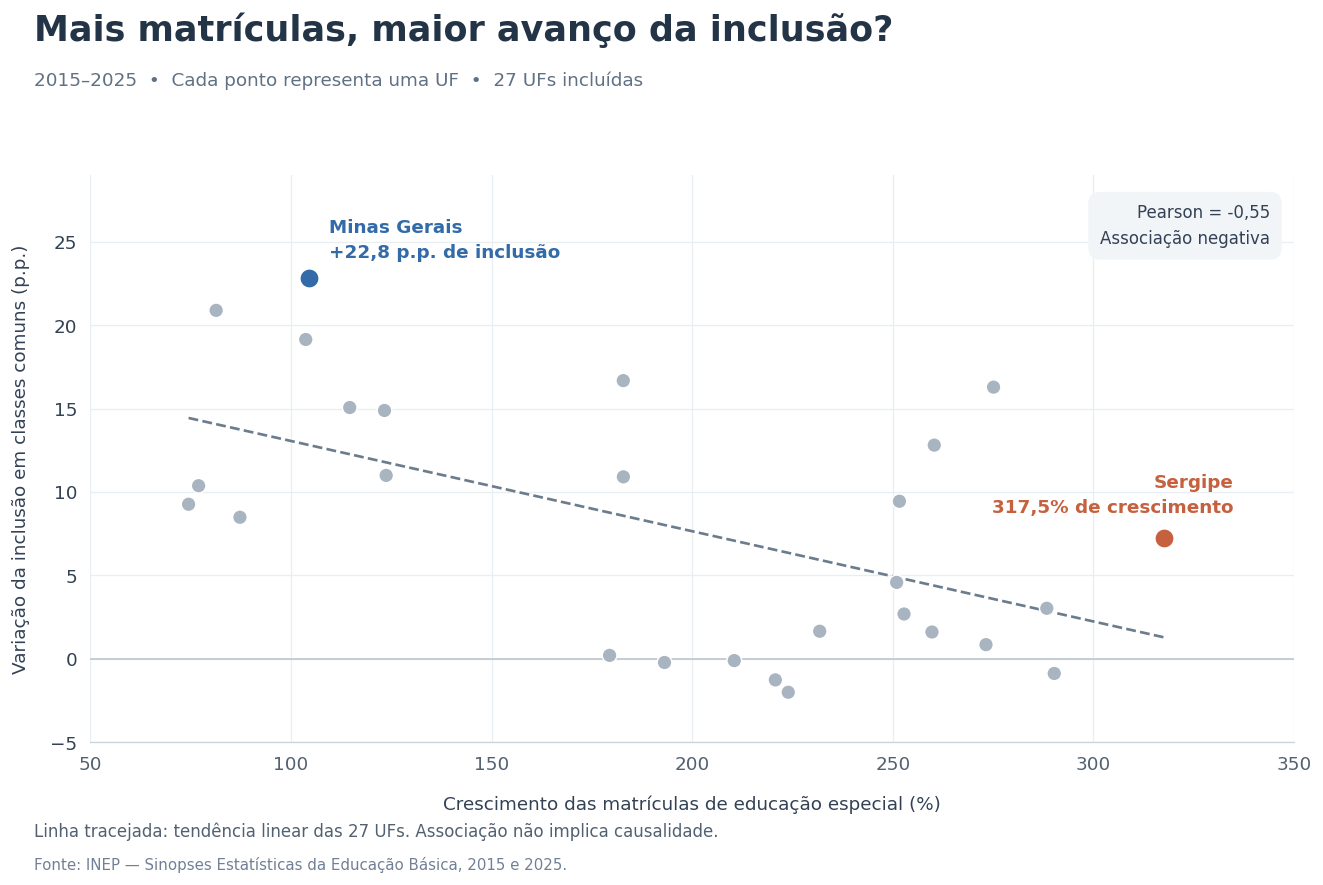

In [17]:
x = dados['crescimento_2025']
y = dados['ganho_2025']
fig, ax = plt.subplots(figsize=(11.8, 7.5))
fig.subplots_adjust(left=0.10, right=0.95, bottom=0.17, top=0.80)

# A linha resume a tendência linear usando os dados das 27 UFs.
inclinacao, intercepto = np.polyfit(x, y, 1)
x_linha = np.array([x.min(), x.max()])
ax.plot(x_linha, inclinacao * x_linha + intercepto,
        color='#6B7C8C', linestyle='--', linewidth=1.6, zorder=1)

# Os demais estados permanecem visíveis em cinza.
ax.scatter(x, y, s=78, color=dados['cor'], edgecolors='white', linewidths=0.9, zorder=3)
for sigla, cor in cores_destaque.items():
    linha = dados[dados['sigla'] == sigla].iloc[0]
    ax.scatter(linha['crescimento_2025'], linha['ganho_2025'], s=155,
               color=cor, edgecolors='white', linewidths=1.8, zorder=4)
    if sigla == 'MG':
        texto = 'Minas Gerais\n+' + numero_br(linha['ganho_2025']) + ' p.p. de inclusão'
        deslocamento, alinhamento = (12, 12), 'left'
    else:
        texto = 'Sergipe\n' + numero_br(linha['crescimento_2025']) + '% de crescimento'
        deslocamento, alinhamento = (42, 15), 'right'
    ax.annotate(texto, (linha['crescimento_2025'], linha['ganho_2025']),
                xytext=deslocamento, textcoords='offset points', ha=alinhamento,
                color=cor, fontsize=11, weight='bold', linespacing=1.5)

ax.axhline(0, color='#BCC7D1', linewidth=1)
ax.set_xlim(50, 350)
ax.set_ylim(-5, 29)
ax.set_xticks([50, 100, 150, 200, 250, 300, 350])
ax.set_yticks([-5, 0, 5, 10, 15, 20, 25])
ax.set_xlabel('Crescimento das matrículas de educação especial (%)', labelpad=13)
ax.set_ylabel('Variação da inclusão em classes comuns (p.p.)', labelpad=12)
ax.grid(color='#E9EEF2', linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.spines['bottom'].set_color('#CBD4DD')
ax.tick_params(length=0, pad=8)

# Um único coeficiente mantém o gráfico simples de ler.
correlacao = f'Pearson = {pearson[2025]:.2f}'.replace('.', ',')
ax.text(0.98, 0.95, correlacao + '\nAssociação negativa', transform=ax.transAxes,
        ha='right', va='top', fontsize=10, linespacing=1.6, color='#334155',
        bbox={'boxstyle': 'round,pad=0.7', 'facecolor': '#F1F5F8', 'edgecolor': 'none'})

fig.text(0.06, 0.95, 'Mais matrículas, maior avanço da inclusão?',
         fontsize=21, weight='bold', color='#243447')
fig.text(0.06, 0.90, '2015–2025  •  Cada ponto representa uma UF  •  27 UFs incluídas',
         fontsize=11, color='#607184')
fig.text(0.06, 0.065, 'Linha tracejada: tendência linear das 27 UFs. Associação não implica causalidade.',
         fontsize=10, color='#526171')
fig.text(0.06, 0.028, 'Fonte: INEP — Sinopses Estatísticas da Educação Básica, 2015 e 2025.',
         fontsize=9, color='#718096')
plt.show()

## 7.4) Comparação por estado

Os dois painéis mantêm **as mesmas UFs na mesma ordem**, do maior para o menor crescimento das matrículas. Leia cada linha da esquerda para a direita. Os valores à direita de zero no segundo painel indicam aumento da inclusão; à esquerda, redução.

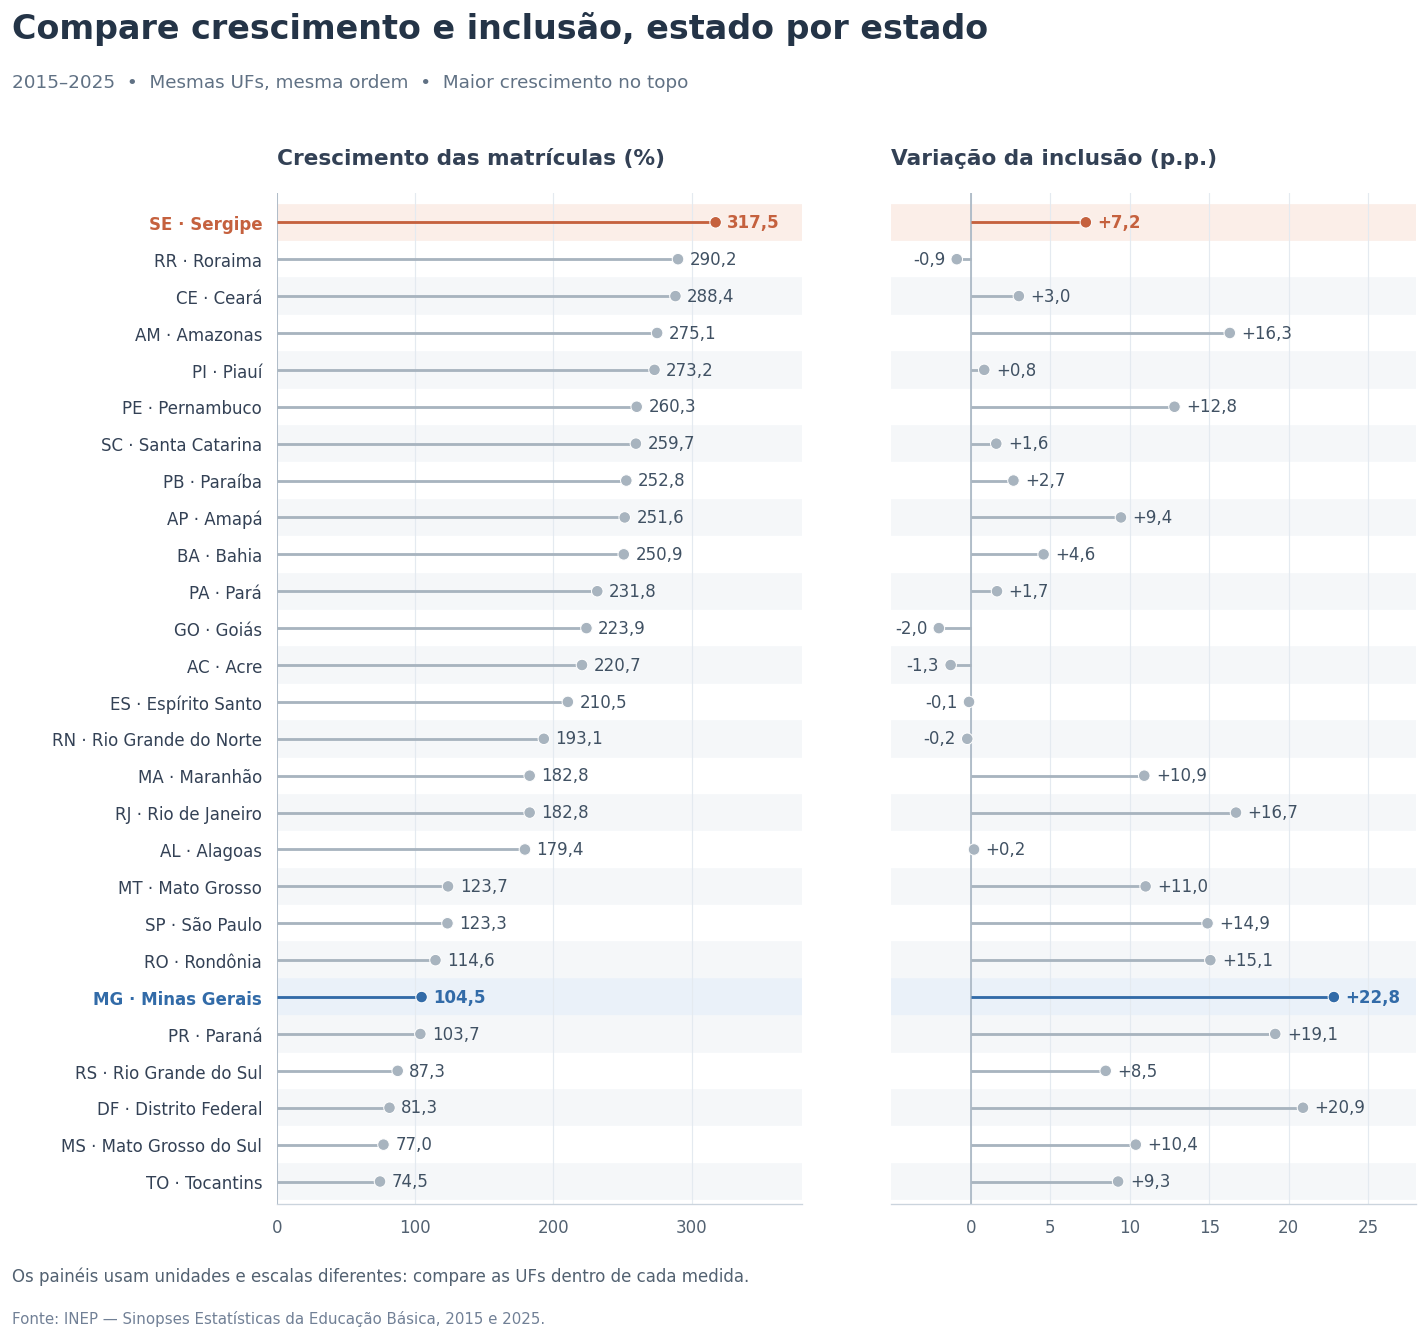

In [18]:
# A mesma ordenação permite comparar os dois indicadores de cada UF.
ranking = dados.sort_values('crescimento_2025', ascending=False).reset_index(drop=True)
fig, eixos = plt.subplots(1, 2, figsize=(13, 11.7), sharey=True,
                          gridspec_kw={'width_ratios': [1, 1]})
fig.subplots_adjust(left=0.23, right=0.96, bottom=0.12, top=0.84, wspace=0.17)

colunas = ['crescimento_2025', 'ganho_2025']
titulos = ['Crescimento das matrículas (%)', 'Variação da inclusão (p.p.)']

for ax, coluna, titulo in zip(eixos, colunas, titulos):
    # Faixas claras ajudam a seguir a mesma linha nos dois painéis.
    for i, linha in ranking.iterrows():
        if linha['sigla'] == 'MG':
            ax.axhspan(i - 0.48, i + 0.48, color='#EAF1F9', zorder=0)
        elif linha['sigla'] == 'SE':
            ax.axhspan(i - 0.48, i + 0.48, color='#FBEEE8', zorder=0)
        elif i % 2 == 0:
            ax.axhspan(i - 0.48, i + 0.48, color='#F5F7F9', zorder=0)

    # Cada ponto mostra o valor; a linha começa em zero.
    ax.hlines(ranking.index, 0, ranking[coluna], colors=ranking['cor'], linewidth=1.7, zorder=2)
    ax.scatter(ranking[coluna], ranking.index, c=ranking['cor'], s=48,
               edgecolors='white', linewidths=0.6, zorder=3)
    ax.axvline(0, color='#A7B5C2', linewidth=1, zorder=1)
    for i, linha in ranking.iterrows():
        valor = linha[coluna]
        destaque = linha['sigla'] in cores_destaque
        texto = numero_br(valor, sinal=coluna == 'ganho_2025')
        ax.annotate(texto, (valor, i), xytext=(7 if valor >= 0 else -7, 0),
                    textcoords='offset points', va='center',
                    ha='left' if valor >= 0 else 'right', fontsize=10,
                    weight='bold' if destaque else 'normal',
                    color=linha['cor'] if destaque else '#405163')
    ax.set_title(titulo, loc='left', fontsize=13, weight='bold', color='#334155', pad=17)
    ax.grid(axis='x', color='#E4EAF0', linewidth=0.7)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right', 'left']].set_visible(False)
    ax.spines['bottom'].set_color('#CBD4DD')
    ax.tick_params(axis='both', length=0, pad=9, labelsize=10)

eixos[0].set_yticks(ranking.index, ranking['sigla'] + ' · ' + ranking['uf'])
eixos[0].set_ylim(len(ranking) - 0.4, -0.8)
eixos[0].set_xlim(0, 380)
eixos[0].set_xticks([0, 100, 200, 300])
eixos[1].set_xlim(-5, 28)
eixos[1].set_xticks([0, 5, 10, 15, 20, 25])
eixos[1].tick_params(labelleft=False)

# As cores e o negrito reforçam os mesmos dois exemplos da dispersão.
for rotulo, sigla in zip(eixos[0].get_yticklabels(), ranking['sigla']):
    if sigla in cores_destaque:
        rotulo.set_color(cores_destaque[sigla])
        rotulo.set_weight('bold')

fig.text(0.06, 0.95, 'Compare crescimento e inclusão, estado por estado',
         fontsize=20, weight='bold', color='#243447')
fig.text(0.06, 0.915, '2015–2025  •  Mesmas UFs, mesma ordem  •  Maior crescimento no topo',
         fontsize=11, color='#607184')
fig.text(0.06, 0.065, 'Os painéis usam unidades e escalas diferentes: compare as UFs dentro de cada medida.',
         fontsize=10, color='#526171')
fig.text(0.06, 0.035, 'Fonte: INEP — Sinopses Estatísticas da Educação Básica, 2015 e 2025.',
         fontsize=9, color='#718096')
plt.show()

## 7.5) Leitura dos resultados

**Não, na comparação entre as UFs.** O maior crescimento não correspondeu aos maiores ganhos de inclusão; a associação linear foi negativa (**Pearson ≈ −0,55**).

- **Sergipe:** matrículas **+317,5%**; inclusão **+7,2 p.p.**
- **Minas Gerais:** matrículas **+104,5%**; inclusão **+22,8 p.p.**
- **Brasil:** matrículas **+164,1%**; inclusão de **80,7% para 93,5%** (**+12,8 p.p.**). O percentual nacional usa a soma das matrículas.

**O ponto de partida importa:** uma UF que já tinha 95% em classes comuns só poderia ganhar 5 p.p. até chegar a 100%. Por isso, um ganho pequeno pode coexistir com um percentual final alto.

**Limites:** associação não demonstra causa e efeito. A análise descreve UFs, não alunos ou escolas; mudanças no registro das matrículas podem afetar a comparação entre anos.

## 7.6) Verificação complementar · 2015–2020

Repetimos os cálculos com 2020 como ano final. A associação também é negativa nesse intervalo. Spearman compara as posições das UFs nos rankings, complementando a correlação linear.

In [19]:
# Conferência resumida dos dois períodos, sem repetir os gráficos principais.
from IPython.display import display

comparacao_periodos = pd.DataFrame({
    'Período': ['2015–2020', '2015–2025'],
    'Pearson': [pearson[2020], pearson[2025]],
    'Spearman': [spearman[2020], spearman[2025]]
}).set_index('Período')
display(comparacao_periodos.round(2))

,Pearson,Spearman
Período,,
2015–2020,-0.59,-0.56
2015–2025,-0.55,-0.44


**Fonte:** [INEP — Sinopses Estatísticas da Educação Básica](https://www.gov.br/inep/pt-br/acesso-a-informacao/dados-abertos/sinopses-estatisticas/educacao-basica). Totais por UF: tabelas 1.38 (total) e 1.39 (classes comuns) em 2015/2020; tabela 1.55 em 2025. Os dados estão incorporados ao notebook.

## Conclusão

Entre 2015 e 2025, a educação especial passou de **1,91% para 5,34%** das matrículas da educação básica. No mesmo período, a parcela das matrículas da educação especial em classes comuns passou de **80,7% para 93,5%** no Brasil.

Na comparação entre as 27 UFs, a participação da educação especial nas matrículas de 2025 teve uma associação maior com o percentual de pessoas com diagnóstico de autismo do que com o percentual de pessoas com deficiência no Censo de 2022.

A comparação de matrículas cobre três anos específicos: 2015, 2020 e 2025. As correlações descrevem diferenças entre UFs e os dois indicadores do IBGE foram divulgados com uma casa decimal.